# TDA practice: from simplices to landscapes

Hands-on companion to the two study notes (`01_Homology_for_TDA.pdf`, `02_Persistent_Homology_for_TDA.pdf`).

1. Simplicial homology by hand: boundary matrices over $\mathbb{Z}/2$, Betti numbers, Euler characteristic
2. Rips persistence of point clouds sampled from a circle, a sphere, a torus and an annulus (ripser)
3. Noise and stability (bottleneck distance)
4. Persistence landscapes and their $L^p$ norms (own implementation in `tda_utils.py`)
5. From a time series to point clouds: sliding windows, and the volatility-scaling caveat
6. A first look at real data: KOSPI / KOSPI200 / KOSDAQ around the 2020 crash

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from ripser import ripser
from persim import plot_diagrams, bottleneck
import tda_utils as T
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(0)

## 1. Simplicial homology by hand

The complex of Figure 2 in study note 1: vertices $a,\dots,g$, seven edges, one filled triangle $\{d,e,f\}$.
With $\mathbb{Z}/2$ coefficients a chain is a 0/1 vector and the boundary map is a 0/1 matrix; $b_n=\dim\ker\partial_n-\operatorname{rank}\partial_{n+1}$.

In [2]:
def rank_gf2(M):
    # Gaussian elimination over Z/2 (XOR rows)
    M = M.copy() % 2; r = 0
    for c in range(M.shape[1]):
        piv = np.where(M[r:, c] == 1)[0]
        if len(piv) == 0: continue
        p = piv[0] + r; M[[r, p]] = M[[p, r]]
        for i in range(M.shape[0]):
            if i != r and M[i, c] == 1: M[i] ^= M[r]
        r += 1
        if r == M.shape[0]: break
    return r

def boundary_matrix(lower, upper):
    # rows = lower simplices, cols = upper simplices, entry 1 if row is a face of column
    return np.array([[1 if set(l) <= set(u) else 0 for u in upper] for l in lower], dtype=np.uint8)

def betti_numbers(simplices):
    by_dim = {}
    for s in simplices: by_dim.setdefault(len(s) - 1, []).append(tuple(sorted(s)))
    top = max(by_dim); out = []
    for n in range(top + 1):
        k = len(by_dim[n])
        rank_dn = rank_gf2(boundary_matrix(by_dim[n - 1], by_dim[n])) if n > 0 else 0
        rank_dn1 = rank_gf2(boundary_matrix(by_dim[n], by_dim[n + 1])) if n + 1 in by_dim else 0
        out.append((k - rank_dn) - rank_dn1)          # dim Z_n - dim B_n
    return out

V = list("abcdefg")
K = [(v,) for v in V] + [("a","b"),("b","c"),("a","c"),("b","d"),("d","e"),("e","f"),("d","f")] + [("d","e","f")]
b = betti_numbers(K)
print("Betti numbers b0, b1, b2 =", b)
k = [sum(len(s) == n + 1 for s in K) for n in range(3)]
print("Euler characteristic: simplices", k[0]-k[1]+k[2], "| Betti", b[0]-b[1]+b[2])

Betti numbers b0, b1, b2 = [2, 1, 0]
Euler characteristic: simplices 1 | Betti 1


In [3]:
# the same complex with the hollow triangle filled too: the loop dies, b1 -> 0
K2 = K + [("a","b","c")]
print("after filling {a,b,c}:", betti_numbers(K2))
# a hollow tetrahedron (4 triangles, no 3-simplex) is a sphere: b = 1, 0, 1
import itertools
S2 = [s for n in (1, 2, 3) for s in itertools.combinations("wxyz", n)]
print("hollow tetrahedron:", betti_numbers(S2))

after filling {a,b,c}: [2, 0, 0]
hollow tetrahedron: [1, 0, 1]


## 2. Rips persistence of sampled shapes

`ripser` computes the Vietoris–Rips persistence with $\mathbb{Z}/2$ coefficients. Long bars far from the diagonal are the Betti numbers of the sampled shape;
short bars near the diagonal are sampling noise. The $H_0$ diagram always has one point at infinity (the whole cloud is connected eventually).

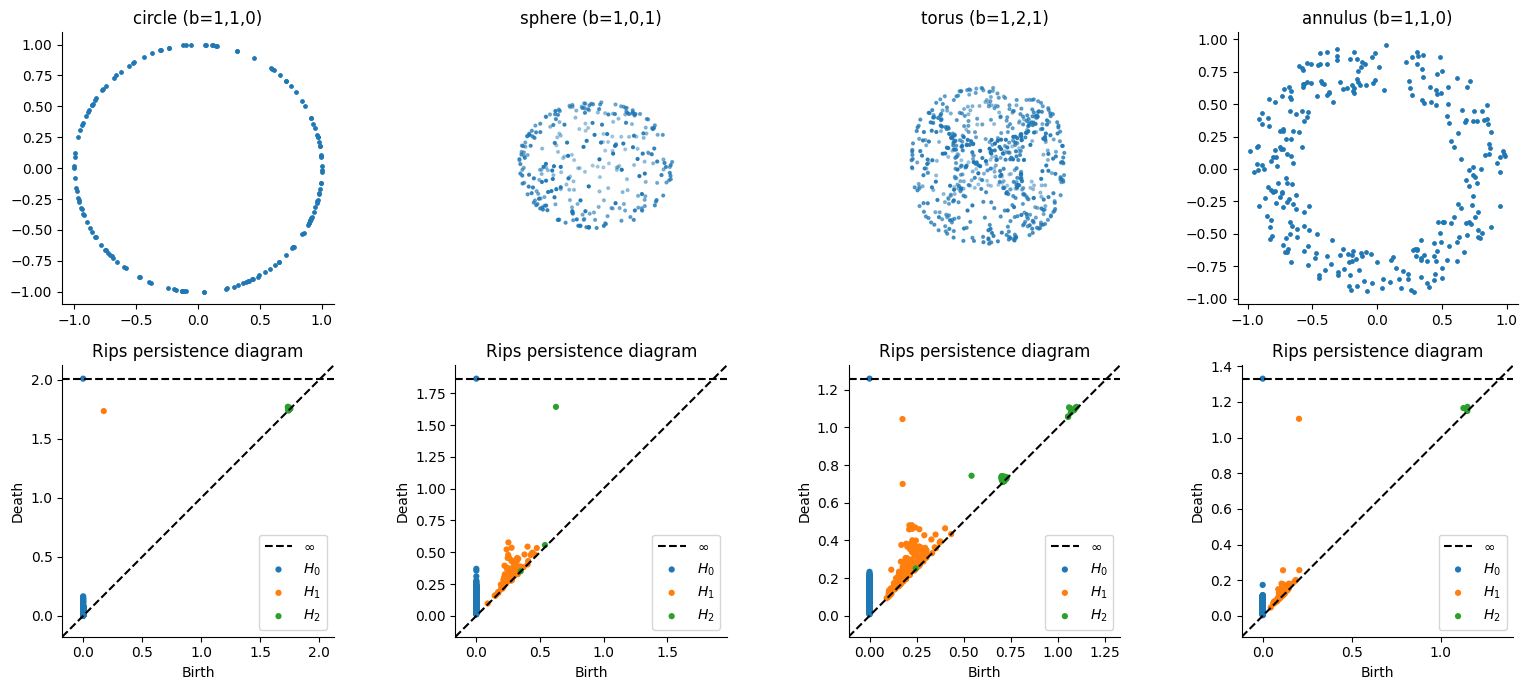

In [4]:
def sample_circle(n, noise=0.0):
    t = rng.uniform(0, 2*np.pi, n); return np.c_[np.cos(t), np.sin(t)] + rng.normal(0, noise, (n, 2))
def sample_sphere(n):
    x = rng.normal(size=(n, 3)); return x / np.linalg.norm(x, axis=1, keepdims=True)
def sample_torus(n, R=1.0, r=0.4):
    u, v = rng.uniform(0, 2*np.pi, n), rng.uniform(0, 2*np.pi, n)
    return np.c_[(R + r*np.cos(v))*np.cos(u), (R + r*np.cos(v))*np.sin(u), r*np.sin(v)]
def sample_annulus(n, r0=0.6, r1=1.0):
    t = rng.uniform(0, 2*np.pi, n); rad = np.sqrt(rng.uniform(r0**2, r1**2, n)); return np.c_[rad*np.cos(t), rad*np.sin(t)]

clouds = {"circle (b=1,1,0)": sample_circle(150), "sphere (b=1,0,1)": sample_sphere(300),
          "torus (b=1,2,1)": sample_torus(600), "annulus (b=1,1,0)": sample_annulus(300)}
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for j, (name, P) in enumerate(clouds.items()):
    dg = ripser(P, maxdim=2)["dgms"]
    ax = axes[0, j]
    if P.shape[1] == 2: ax.scatter(P[:, 0], P[:, 1], s=6); ax.set_aspect("equal")
    else: ax.remove(); ax = fig.add_subplot(2, 4, j + 1, projection="3d"); ax.scatter(P[:, 0], P[:, 1], P[:, 2], s=4); ax.set_axis_off()
    ax.set_title(name)
    plot_diagrams(dg, ax=axes[1, j], show=False); axes[1, j].set_title("Rips persistence diagram")
plt.tight_layout(); plt.show()

In [5]:
def long_bars(dgms, min_life):
    # count finite bars with lifetime > min_life in each dimension (the "persistent" Betti numbers)
    out = []
    for d in dgms:
        f = d[np.isfinite(d[:, 1])]; out.append(int(((f[:, 1] - f[:, 0]) > min_life).sum()))
    return out

for thr in [0.5, 0.3]:
    print(f"persistent Betti numbers (bars longer than {thr}), plus the one infinite H0 bar:")
    for name, P in clouds.items():
        dg = ripser(P, maxdim=2)["dgms"]
        lb = long_bars(dg, thr); lb[0] += 1
        print(f"  {name:20s} ->", lb)

persistent Betti numbers (bars longer than 0.5), plus the one infinite H0 bar:


  circle (b=1,1,0)     -> [1, 1, 0]


  sphere (b=1,0,1)     -> [1, 0, 1]


  torus (b=1,2,1)      -> [1, 2, 0]


  annulus (b=1,1,0)    -> [1, 1, 0]
persistent Betti numbers (bars longer than 0.3), plus the one infinite H0 bar:


  circle (b=1,1,0)     -> [1, 1, 0]


  sphere (b=1,0,1)     -> [4, 1, 1]


  torus (b=1,2,1)      -> [1, 2, 0]


  annulus (b=1,1,0)    -> [1, 1, 0]


The torus is the hard case. Its two loops are found, but its void ($b_2$) is not: with 600 points the $H_2$ bar is shorter than the sampling-noise bars,
so no single cut-off separates it (lowering the cut-off to $0.3$ instead starts splitting the sphere's $H_0$). The void needs a denser sample or a per-dimension cut-off.
This is the practical content of the stability theorem: a feature is visible when its size is well above the typical gap between sample points.

## 3. Noise and stability

Move the points a little, and the diagram moves a little: $d_B(D(X), D(Y)) \le 2\,d_H(X, Y)$ (Rips, diameter convention).

In [6]:
base = sample_circle(120)
rows = []
for s in [0.0, 0.03, 0.06, 0.1, 0.15, 0.2]:
    P = base + rng.normal(0, s, base.shape)
    d1 = ripser(P, maxdim=1)["dgms"][1]
    d1_base = ripser(base, maxdim=1)["dgms"][1]
    dH = max(np.linalg.norm(P - base, axis=1).max(), 0)       # points moved one-to-one, so this bounds the Hausdorff distance
    life = np.sort(d1[:, 1] - d1[:, 0])[::-1]
    rows.append({"noise sd": s, "Hausdorff <=": round(dH, 3), "bottleneck H1": round(bottleneck(d1_base, d1), 3),
                 "longest H1 bar": round(life[0], 3), "2nd longest": round(life[1], 3) if len(life) > 1 else 0})
pd.DataFrame(rows)

,noise sd,Hausdorff <=,bottleneck H1,longest H1 bar,2nd longest
0,0.00,0.000,0.000,1.491,0.000
1,0.03,0.099,0.055,1.433,0.011
2,0.06,0.199,0.152,1.338,0.016
3,0.10,0.303,0.291,1.164,0.073
4,0.15,0.435,0.377,1.051,0.043
5,0.20,0.582,0.547,0.813,0.114


The bottleneck distance stays below $2\times$ the Hausdorff bound, as the theorem says. The longest bar (the circle) shrinks slowly, the second longest grows
with the noise; the gap between them is the margin we have for reading "one loop".

## 4. Persistence landscapes and $L^p$ norms

`tda_utils.landscape` evaluates $\lambda_k$ on a grid; `landscape_norm` integrates. For non-overlapping tents the norms have closed forms
$\|\lambda\|_1=\frac14\sum\ell_j^2$ and $\|\lambda\|_2=(\frac1{12}\sum\ell_j^3)^{1/2}$, which we use to check the implementation.

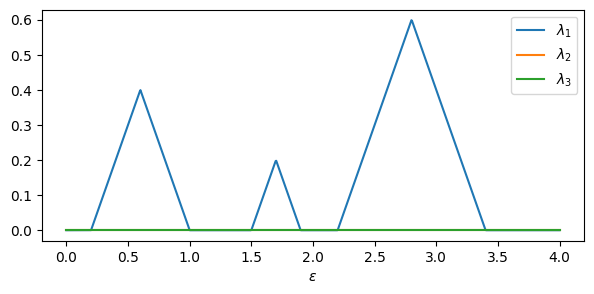

L1  numeric 0.5600  closed form 0.5600
L2  numeric 0.4382  closed form 0.4382


In [7]:
dgm = np.array([[0.2, 1.0], [1.5, 1.9], [2.2, 3.4]])          # three non-overlapping tents
grid = np.linspace(0, 4, 800)
lam = T.landscape(dgm, grid, k_max=3)
fig, ax = plt.subplots(figsize=(7, 3))
for k in range(3): ax.plot(grid, lam[k], label=f"$\\lambda_{k+1}$")
ax.set_xlabel("$\\epsilon$"); ax.legend(); plt.show()
l = dgm[:, 1] - dgm[:, 0]
print("L1  numeric %.4f  closed form %.4f" % (T.landscape_norm(dgm, 1), (l**2).sum()/4))
print("L2  numeric %.4f  closed form %.4f" % (T.landscape_norm(dgm, 2), np.sqrt((l**3).sum()/12)))

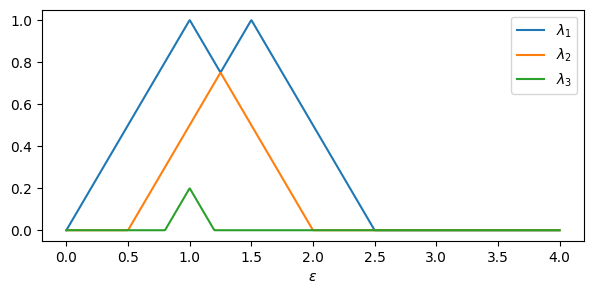

L1  numeric 2.0400  closed form 2.0400
landscape of the circle samples: ||lambda||_1 for the three shapes
  circle (b=1,1,0)     H1 L1 = 0.609
  sphere (b=1,0,1)     H1 L1 = 0.188


  torus (b=1,2,1)      H1 L1 = 0.525
  annulus (b=1,1,0)    H1 L1 = 0.217


In [8]:
# overlapping tents: lambda_1 and lambda_2 share the mass, but the norms still equal the closed forms
dgm2 = np.array([[0.0, 2.0], [0.5, 2.5], [0.8, 1.2]])
lam2 = T.landscape(dgm2, grid, 3)
fig, ax = plt.subplots(figsize=(7, 3))
for k in range(3): ax.plot(grid, lam2[k], label=f"$\\lambda_{k+1}$")
ax.set_xlabel("$\\epsilon$"); ax.legend(); plt.show()
l = dgm2[:, 1] - dgm2[:, 0]
print("L1  numeric %.4f  closed form %.4f" % (T.landscape_norm(dgm2, 1), (l**2).sum()/4))
print("landscape of the circle samples: ||lambda||_1 for the three shapes")
for name, P in clouds.items():
    print(f"  {name:20s} H1 L1 = {T.landscape_norm(T.rips_h1(P), 1):.3f}")

## 5. From a time series to point clouds

Two synthetic "return" series with a calm regime and a stressed regime. Each day is a point $x_t\in\mathbb{R}^2$; a window of $w$ days is a cloud;
we record $\|\lambda\|_1$ of its $H_1$ diagram. The norm is much larger in the stressed regime, but note the **scaling caveat**: multiplying all returns
by 2 multiplies $\|\lambda\|_1$ by 4. The TDA norm is not scale-free, so in the real-data notebooks it is always compared with realized volatility.

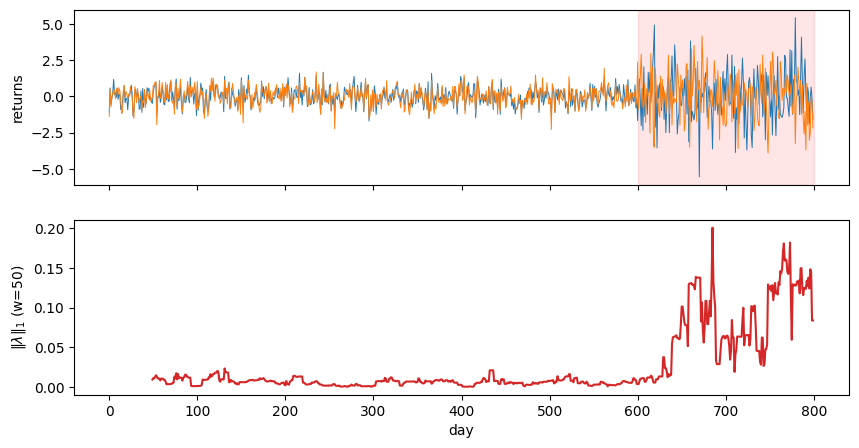

scaling check: norm(2x) / norm(x) = 4.0


In [9]:
n = 400
calm = rng.multivariate_normal([0, 0], [[1, .8], [.8, 1]], n) * 0.6
stress = np.r_[rng.multivariate_normal([0, 0], [[1, .8], [.8, 1]], n//2) * 0.6,
               rng.multivariate_normal([0, 0], [[1, -.3], [-.3, 1]], n//2) * 1.6]
series = pd.DataFrame(np.r_[calm, stress], columns=["A", "B"])
ns = T.norm_series(series, w=50)
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(series.values, lw=.7); axes[0].set_ylabel("returns"); axes[0].axvspan(600, 800, color="red", alpha=.1)
axes[1].plot(ns.index, ns["L1"], color="C3"); axes[1].set_ylabel("$\\|\\lambda\\|_1$ (w=50)"); axes[1].set_xlabel("day")
plt.show()
print("scaling check: norm(2x) / norm(x) =", (T.norm_series(series*2, w=50)["L1"] / ns["L1"]).replace([np.inf], np.nan).dropna().median().round(3))

## 6. Real data: three Korean indices around the 2020 crash

`data/kr_indices_raw.csv` holds KOSPI, KOSPI200 and KOSDAQ closes (FinanceDataReader). Log returns are multiplied by 100 (percent) so the norms are readable.
The full analysis (four events, Kendall $\tau$, false-alarm test, comparison with volatility) is in `04_korea_crash_tda.ipynb`.

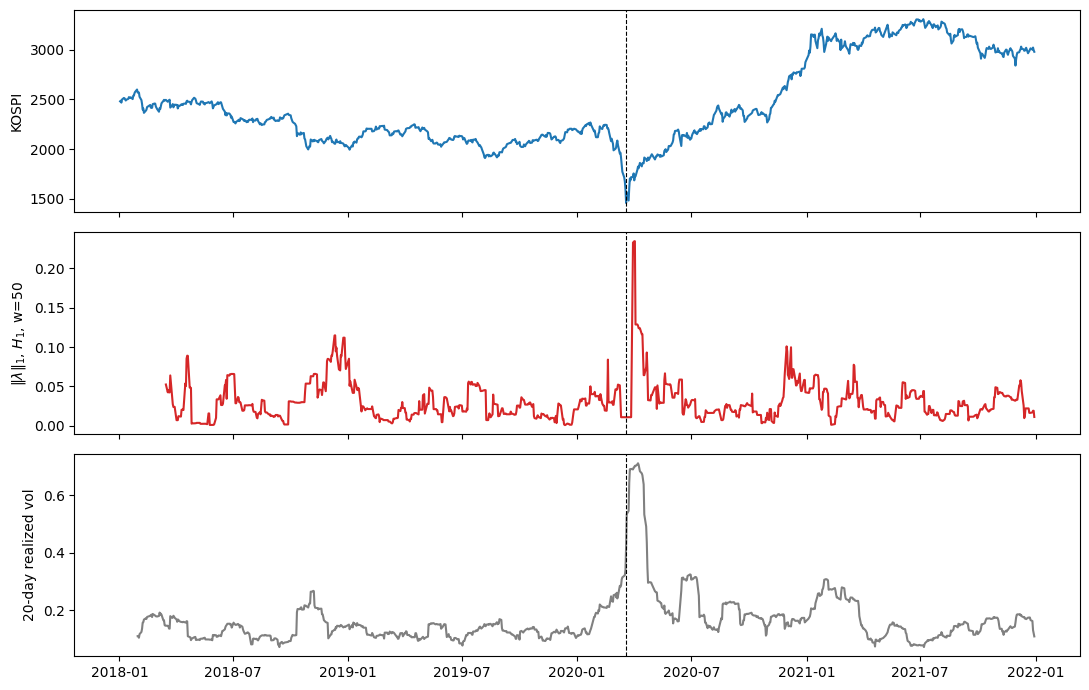

correlation of log L1 with log realized vol: 0.316


In [10]:
kr = pd.read_csv("data/kr_indices_raw.csv", index_col=0, parse_dates=True)
r = T.log_returns(kr.loc["2018":"2021"]) * 100
ns = T.norm_series(r, w=50)
vol = T.realized_vol(r["KOSPI"] / 100, 20)
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
axes[0].plot(kr.loc["2018":"2021", "KOSPI"]); axes[0].set_ylabel("KOSPI")
axes[1].plot(ns["L1"], color="C3"); axes[1].set_ylabel("$\\|\\lambda\\|_1$, $H_1$, w=50")
axes[2].plot(vol, color="gray"); axes[2].set_ylabel("20-day realized vol")
for ax in axes: ax.axvline(pd.Timestamp("2020-03-19"), color="k", ls="--", lw=.8)
plt.tight_layout(); plt.show()
print("correlation of log L1 with log realized vol:", np.corrcoef(np.log(ns["L1"] + 1e-9).reindex(vol.index).dropna(),
      np.log(vol.reindex(ns.index).dropna()))[0, 1].round(3))

Already here the main tension of the method is visible: the landscape norm spikes **during** the crash (March 2020) together with volatility, and
whether it also rises *before* the crash, and more than volatility does, is exactly the question for notebook 04.